In [1]:
!pip install nltk -q
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

print("DONE")

DONE


In [2]:
files = {
    'imdb':  'imdb_labelled.txt',
    'amazon':'amazon_cells_labelled.txt',
    'yelp':  'yelp_labelled.txt'
}

dfs = []
for source, path in files.items():
    df = pd.read_csv(path, sep='\t', header=None, names=['text', 'label'])
    df['source'] = source
    dfs.append(df)

data = pd.concat(dfs, ignore_index=True)

print("Total rows:", len(data))
print(data['label'].value_counts())
print(data.head())

Total rows: 2748
label
1    1386
0    1362
Name: count, dtype: int64
                                                text  label source
0  A very, very, very slow-moving, aimless movie ...      0   imdb
1  Not sure who was more lost - the flat characte...      0   imdb
2  Attempting artiness with black & white and cle...      0   imdb
3       Very little music or anything to speak of.        0   imdb
4  The best scene in the movie was when Gerardo i...      1   imdb


In [3]:
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

data['clean_text'] = data['text'].apply(clean_text)

for i in range(5):
    print("ORIGINAL:", data['text'].iloc[i])
    print("CLEANED :", data['clean_text'].iloc[i])
    print("-" * 60)

ORIGINAL: A very, very, very slow-moving, aimless movie about a distressed, drifting young man.  
CLEANED : a very very very slow moving aimless movie about a distressed drifting young man
------------------------------------------------------------
ORIGINAL: Not sure who was more lost - the flat characters or the audience, nearly half of whom walked out.  
CLEANED : not sure who was more lost the flat characters or the audience nearly half of whom walked out
------------------------------------------------------------
ORIGINAL: Attempting artiness with black & white and clever camera angles, the movie disappointed - became even more ridiculous - as the acting was poor and the plot and lines almost non-existent.  
CLEANED : attempting artiness with black white and clever camera angles the movie disappointed became even more ridiculous as the acting was poor and the plot and lines almost non existent
------------------------------------------------------------
ORIGINAL: Very little musi

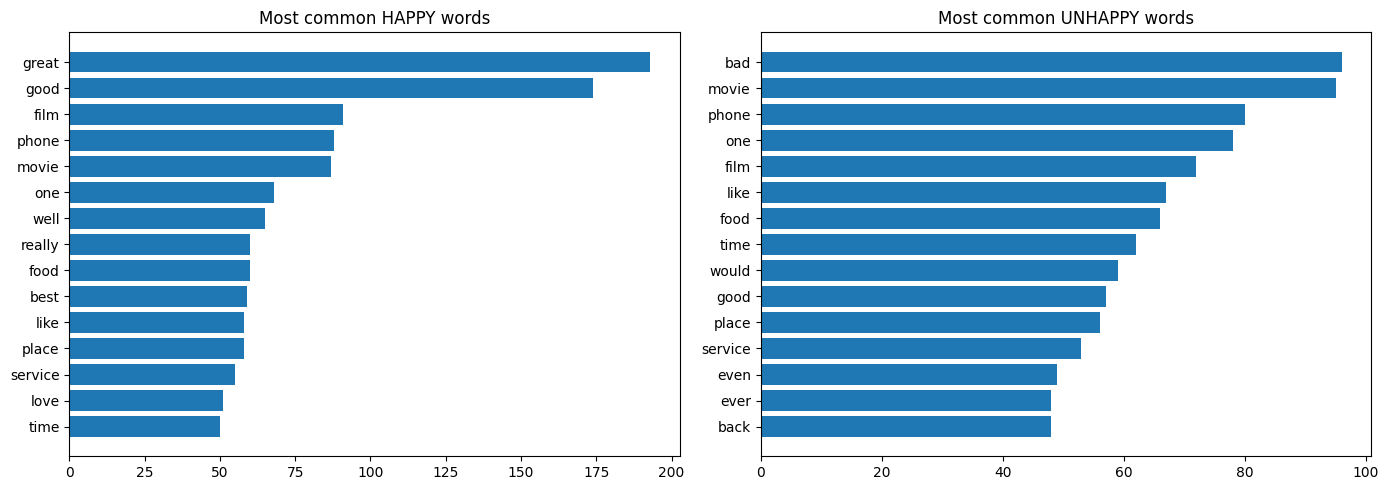

In [4]:
from collections import Counter

def top_words(series, n=15):
    words = ' '.join(series).split()
    words = [w for w in words if w not in stop_words]
    return Counter(words).most_common(n)

pos_top = top_words(data[data.label == 1]['clean_text'])
neg_top = top_words(data[data.label == 0]['clean_text'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, top, title in zip(axes, [pos_top, neg_top], ['Most common HAPPY words', 'Most common UNHAPPY words']):
    words, counts = zip(*top)
    ax.barh(words[::-1], counts[::-1])
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [6]:
X = data['clean_text']
y = data['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training examples:", len(X_train))
print("Testing examples :", len(X_test))

Training examples: 2198
Testing examples : 550


In [7]:
bow = CountVectorizer(max_features=5000)
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))

X_train_bow   = bow.fit_transform(X_train)
X_test_bow    = bow.transform(X_test)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print("BOW vocab size:", len(bow.vocabulary_))
print("TFIDF vocab size:", len(tfidf.vocabulary_))

BOW vocab size: 4388
TFIDF vocab size: 5000


In [8]:
def evaluate(model, X_tr, y_tr, X_te, y_te, name):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    return {
        'Model': name,
        'Accuracy':  round(accuracy_score(y_te, pred), 4),
        'Precision': round(precision_score(y_te, pred), 4),
        'Recall':    round(recall_score(y_te, pred), 4),
        'F1':        round(f1_score(y_te, pred), 4),
    }, model, pred

results = []
models = {}

for vec_name, Xtr, Xte in [('BOW', X_train_bow, X_test_bow), ('TF-IDF', X_train_tfidf, X_test_tfidf)]:
    for model_name, model in [('LogReg', LogisticRegression(max_iter=1000)), ('SVM', LinearSVC())]:
        r, fitted, pred = evaluate(model, Xtr, y_train, Xte, y_test, f"{model_name}-{vec_name}")
        results.append(r)
        models[f"{model_name}-{vec_name}"] = (fitted, Xte, pred)

results_df = pd.DataFrame(results).sort_values('F1', ascending=False)
print(results_df.to_string(index=False))

        Model  Accuracy  Precision  Recall     F1
      SVM-BOW    0.8073     0.8132  0.8014 0.8073
   SVM-TF-IDF    0.8073     0.8178  0.7942 0.8059
   LogReg-BOW    0.8073     0.8251  0.7834 0.8037
LogReg-TF-IDF    0.8055     0.8269  0.7762 0.8007


Best model: SVM-BOW

              precision    recall  f1-score   support

 Unhappy (0)       0.80      0.81      0.81       273
   Happy (1)       0.81      0.80      0.81       277

    accuracy                           0.81       550
   macro avg       0.81      0.81      0.81       550
weighted avg       0.81      0.81      0.81       550



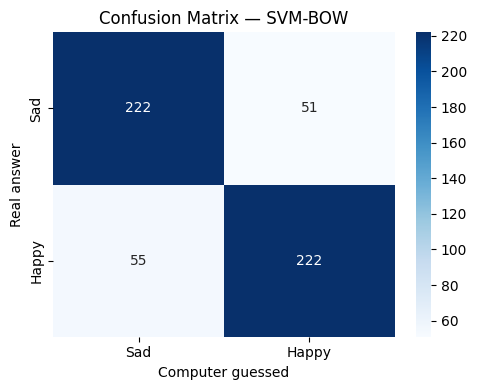

In [9]:
best_name = results_df.iloc[0]['Model']
best_model, best_Xte, best_pred = models[best_name]

print("Best model:", best_name)
print()
print(classification_report(y_test, best_pred, target_names=['Unhappy (0)', 'Happy (1)']))

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Sad', 'Happy'], yticklabels=['Sad', 'Happy'])
plt.xlabel('Computer guessed')
plt.ylabel('Real answer')
plt.title(f'Confusion Matrix — {best_name}')
plt.tight_layout()
plt.show()

In [13]:
test_sentences = [
    "This product is absolutely amazing and I love it.",
    "Worst purchase I have ever made. Total waste of money.",
    "The movie was not good at all.",
    "I expected it to be bad, but actually it was great.",
    "It's okay, nothing special.",
    "Not bad, but not great either.",
]

# This checks which dictionary the winning brain needs!
if 'TF-IDF' in best_name:
    correct_vectorizer = tfidf
else:
    correct_vectorizer = bow

print(f"Using {best_name} for predictions...\n")

for s in test_sentences:
    cleaned = clean_text(s)
    # Use the correct dictionary here
    X_new = correct_vectorizer.transform([cleaned])
    pred = best_model.predict(X_new)[0]
    label = "😊 HAPPY" if pred == 1 else "😞 SAD  "
    print(f"{label}  |  {s}")

Using SVM-BOW for predictions...

😊 HAPPY  |  This product is absolutely amazing and I love it.
😞 SAD    |  Worst purchase I have ever made. Total waste of money.
😞 SAD    |  The movie was not good at all.
😞 SAD    |  I expected it to be bad, but actually it was great.
😞 SAD    |  It's okay, nothing special.
😞 SAD    |  Not bad, but not great either.
